Training Model 1 (MÉT Covid 2020 data)...
Training Model 2 (ZÓNDER Covid 2020 data)...

--- RESULTATEN ---
RMSE MÉT Covid-data (2020)    : 61.64
RMSE ZÓNDER Covid-data (2020) : 65.69
Bestand klaargezet met exact de juiste kolommen!
Excel-bestand 'NW_HVAC_GBM_ASHRAE_metrics.xlsx' succesvol opgeslagen!


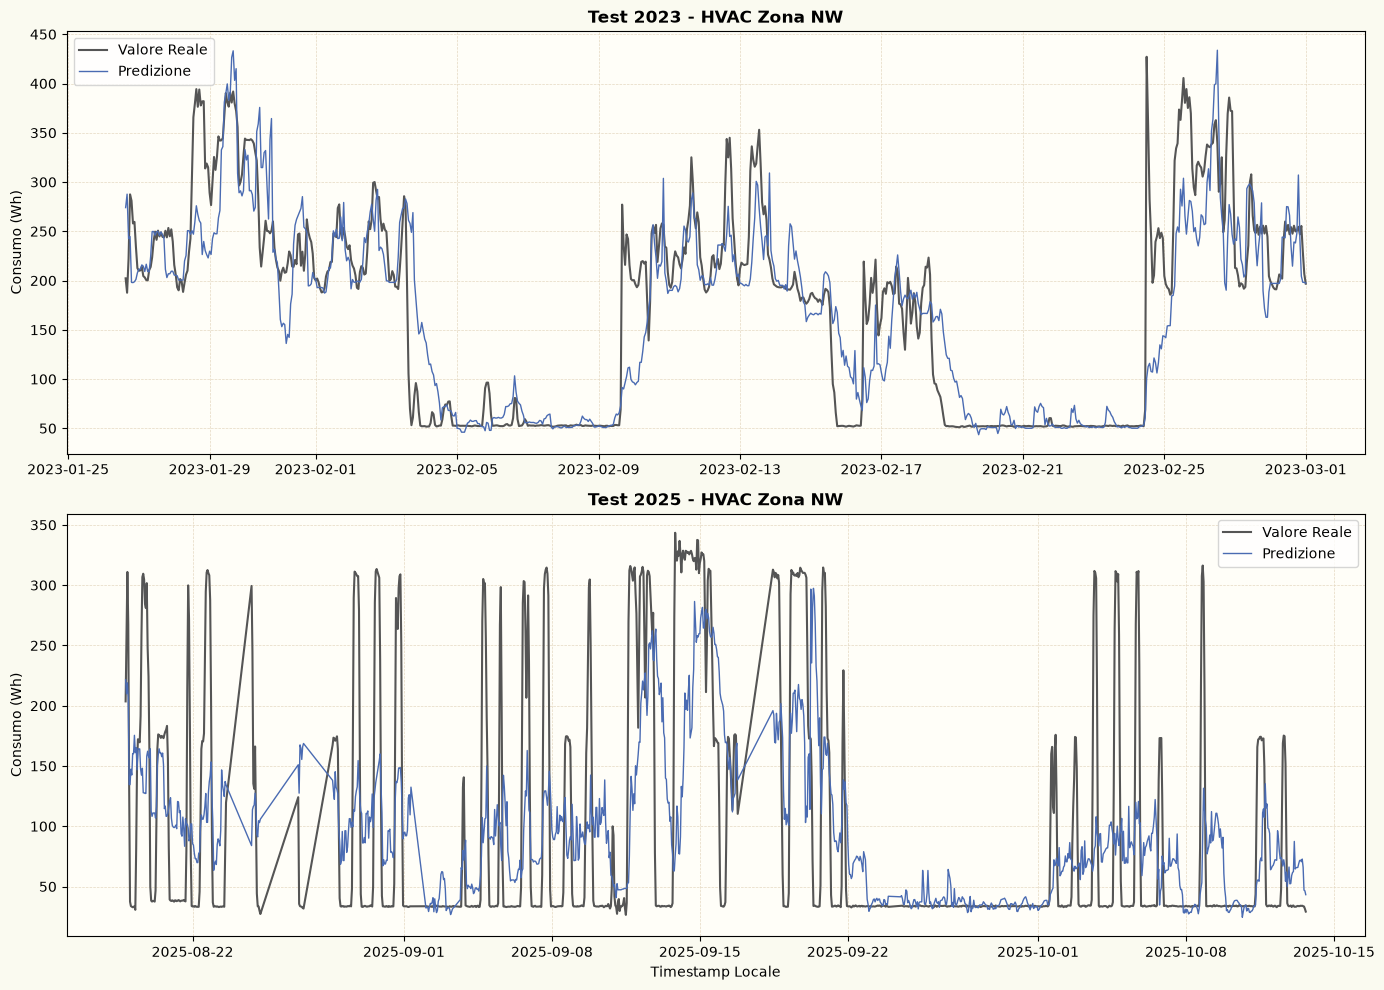

In [20]:
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error

# 1. Laad en filter de data
df = pd.read_csv('cedint_f1_model_ready.csv')
df['timestamp_local'] = pd.to_datetime(df['timestamp_local'])

df_nw_hvac = df[(df['zone'] == 'NW') & (df['load_type'] == 'HVAC')].copy()
df_nw_hvac = df_nw_hvac.sort_values('timestamp_local')

# 2. Bereken de Random Forest 'lag' features
df_nw_hvac['energy_lag_24'] = df_nw_hvac['energy_wh_model'].shift(24)
df_nw_hvac['energy_lag_168'] = df_nw_hvac['energy_wh_model'].shift(168)
df_nw_hvac['temp_lag1'] = df_nw_hvac['temp_c'].shift(1)
df_nw_hvac['temp_lag2'] = df_nw_hvac['temp_c'].shift(2)
df_nw_hvac['roll_mean_24'] = df_nw_hvac['energy_wh_model'].rolling(window=24).mean()
df_nw_hvac['dh_heat'] = (18 - df_nw_hvac['temp_c']).clip(lower=0)
df_nw_hvac['dh_cool'] = (df_nw_hvac['temp_c'] - 24).clip(lower=0)

df_nw_hvac = df_nw_hvac.dropna(subset=['energy_wh_model', 'energy_lag_168', 'roll_mean_24'])

# 3. Stel ALLE vereiste features in (Marie's lijst + Random Forest extra's)
features = [
    "hour_local", "dayofweek_local", "month_local", "is_weekend", "is_holiday", # Tijd
    "temp_c", "dh_cool", "dh_heat", "temp_lag1", "temp_lag2",                   # Temperatuur
    "occupancy", "lum_lux",                                                     # Bezetting & Licht
    "energy_lag_24", "energy_lag_168", "roll_mean_24"                           # Lags
]

X = df_nw_hvac[features].fillna(0)
y = df_nw_hvac['energy_wh_model']

# Test set blijft voor beide modellen hetzelfde
test_mask = df_nw_hvac['include_eval'] == 1
X_test = X[test_mask]
y_test = y[test_mask]

# --- MODEL 1: TRAINING INCLUSIEF COVID (2020) ---
train_mask_with_covid = df_nw_hvac['include_train'] == 1
X_train_with = X[train_mask_with_covid]
y_train_with = y[train_mask_with_covid]

gbm_with = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
print("Training Model 1 (MÉT Covid 2020 data)...")
gbm_with.fit(X_train_with, y_train_with)
preds_with = gbm_with.predict(X_test)
rmse_with = root_mean_squared_error(y_test, preds_with)

# --- MODEL 2: TRAINING EXCLUSIEF COVID (2020) ---
train_mask_no_covid = df_nw_hvac['include_train_no2020'] == 1
X_train_no = X[train_mask_no_covid]
y_train_no = y[train_mask_no_covid]

gbm_no = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
print("Training Model 2 (ZÓNDER Covid 2020 data)...")
gbm_no.fit(X_train_no, y_train_no)
preds_no = gbm_no.predict(X_test)
rmse_no = root_mean_squared_error(y_test, preds_no)

# 4. Vergelijk de resultaten direct met elkaar
print("\n--- RESULTATEN ---")
print(f"RMSE MÉT Covid-data (2020)    : {rmse_with:.2f}")
print(f"RMSE ZÓNDER Covid-data (2020) : {rmse_no:.2f}")

# 5. Sla de voorspellingen op met ALLE verplichte kolommen voor team_b_eval.py
output_df = pd.DataFrame({
    'timestamp_utc': df_nw_hvac.loc[test_mask, 'timestamp_local'],
    'zone': 'NW',
    'load_type': 'HVAC',
    'model': 'gbm',
    'split': 'test',
    'y_true': y_test,      # De echte waardes
    'y_pred': preds_with   # De voorspellingen
})

output_df.to_csv('NW_HVAC_GBM_predictions.csv', index=False)
print("Bestand klaargezet met exact de juiste kolommen!")

import numpy as np
from sklearn.metrics import mean_absolute_error

# --- 5. ZELF DE ASHRAE METRICS BEREKENEN EN EXPORTEREN NAAR EXCEL ---
def calculate_ashrae_metrics(y_true, y_pred, split_name):
    if len(y_true) == 0: return None
    
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mean_y = np.mean(y_true)
    
    # ASHRAE 14 Formules
    cv_rmse = (rmse / mean_y) * 100 if mean_y != 0 else 0
    nmbe = (np.sum(y_true - y_pred) / (n * mean_y)) * 100 if mean_y != 0 else 0
    
    # Strenge limieten: CV(RMSE) <= 30% en NMBE tussen -10% en 10%
    ashrae_pass = (cv_rmse <= 30) and (-10 <= nmbe <= 10)
    
    return {
        'zone': 'NW', 'load': 'HVAC', 'model': 'gbm', 'split': split_name,
        'n': n, 'MAE': mae, 'RMSE': rmse, 'CV_RMSE': cv_rmse, 'NMBE': nmbe, 
        'SHRAE_pass': ashrae_pass
    }

# Filter de testdata op jaar
mask_2023 = test_mask & (df_nw_hvac['timestamp_local'].dt.year == 2023)
mask_2025 = test_mask & (df_nw_hvac['timestamp_local'].dt.year == 2025)

X_2023, y_2023 = X[mask_2023], y[mask_2023]
X_2025, y_2025 = X[mask_2025], y[mask_2025]

# Gebruik het model dat getraind was mét Covid-data (gbm_with)
preds_2023 = gbm_with.predict(X_2023)
preds_2025 = gbm_with.predict(X_2025)

# Metrics verzamelen en als Excel opslaan
metrics = []
if len(y_2023) > 0: metrics.append(calculate_ashrae_metrics(y_2023, preds_2023, 'test_2023'))
if len(y_2025) > 0: metrics.append(calculate_ashrae_metrics(y_2025, preds_2025, 'test_2025'))

df_metrics = pd.DataFrame(metrics)
df_metrics.to_excel('NW_HVAC_GBM_ASHRAE_metrics.xlsx', index=False)
print("Excel-bestand 'NW_HVAC_GBM_ASHRAE_metrics.xlsx' succesvol opgeslagen!")


# --- 6. GRAFIEK GENEREREN IN DE STIJL VAN LUDOVICA ---
import matplotlib.pyplot as plt

# Maak een canvas met de beige achtergrond
fig, axes = plt.subplots(2, 1, figsize=(14, 10), facecolor='#FAFAF0')

# Grafiek 2023
axes[0].plot(df_nw_hvac.loc[X_2023.index, 'timestamp_local'], y_2023, color='#555555', label='Valore Reale', linewidth=1.5)
axes[0].plot(df_nw_hvac.loc[X_2023.index, 'timestamp_local'], preds_2023, color='#4A6BB2', label='Predizione', linewidth=1)
axes[0].set_title('Test 2023 - HVAC Zona NW', fontweight='bold')
axes[0].set_ylabel('Consumo (Wh)')
axes[0].grid(color='#E5D8C1', linestyle='--', linewidth=0.5)
axes[0].legend()
axes[0].set_facecolor('#FFFEF8')

# Grafiek 2025
axes[1].plot(df_nw_hvac.loc[X_2025.index, 'timestamp_local'], y_2025, color='#555555', label='Valore Reale', linewidth=1.5)
axes[1].plot(df_nw_hvac.loc[X_2025.index, 'timestamp_local'], preds_2025, color='#4A6BB2', label='Predizione', linewidth=1)
axes[1].set_title('Test 2025 - HVAC Zona NW', fontweight='bold')
axes[1].set_ylabel('Consumo (Wh)')
axes[1].set_xlabel('Timestamp Locale')
axes[1].grid(color='#E5D8C1', linestyle='--', linewidth=0.5)
axes[1].legend()
axes[1].set_facecolor('#FFFEF8')

plt.tight_layout()
plt.savefig('NW_HVAC_GBM_Grafiek.png', dpi=300)
plt.show()